In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [9]:
monthly_df = pd.read_csv('../Datasets/cleaned/pbs_monthly_cleaned.csv')

In [10]:
monthly_df[['Serial_No','Item','Unit']]

,Serial_No,Item,Unit
0,1,Wheat Flour Bag,20 Kg
1,2,Rice Basmati Broken (Average Quality),1 Kg
2,3,Rice IRRI-6/9 (Sindh/Punjab),1 Kg
3,4,Bread plain (Small Size),Each
4,5,Beef with Bone (Average Quality),1 Kg
5,6,Mutton (Average Quality),1 Kg
6,7,Chicken Farm Broiler (Live),1 Kg
7,8,Milk fresh (Un-boiled),1 Ltr
8,9,Curd (Dahi) Loose,1 Kg
9,10,Powdered Milk NIDO 390 gm Polybag,Each


In [19]:
basket_items = [
    'Wheat Flour Bag',
    'Rice Basmati Broken (Average Quality)',
    'Chicken Farm Broiler (Live)',
    'Milk fresh (Un-boiled)',
    'Eggs Hen (Farm)',
    'Cooking Oil DALDA or Other Similar Brand (SN), 5 Litre Tin',
    'Pulse Masoor (Washed)',
    'Potatoes',
    'Onions',
    'Tomatoes',
    'Sugar Refined'
]

In [21]:
basket_df = monthly_df[monthly_df['Item'].isin(basket_items)]
basket_df[['Item', 'Unit']]

,Item,Unit
0,Wheat Flour Bag,20 Kg
1,Rice Basmati Broken (Average Quality),1 Kg
6,Chicken Farm Broiler (Live),1 Kg
7,Milk fresh (Un-boiled),1 Ltr
10,Eggs Hen (Farm),1 Dozen
12,"Cooking Oil DALDA or Other Similar Brand (SN),...",Each
16,Pulse Masoor (Washed),1 Kg
20,Potatoes,1 Kg
21,Onions,1 Kg
22,Tomatoes,1 Kg


In [22]:
city_columns = monthly_df.columns.drop([
    'Serial_No',
    'Item',
    'Unit',
    'Sep_2026_Avg',
    'Aug_2026_Avg',
    'Sep_2025_Avg',
    'Pct_Change_Monthly',
    'Pct_Change_Yearly'
])

city_columns

Index(['Islamabad', 'Rawalpindi', 'Gujranwala', 'Sialkot', 'Lahore',
       'Faisalabad', 'Sargodha', 'Multan', 'Bahawalpur', 'Karachi',
       'Hyderabad', 'Sukkur', 'Larkana', 'Peshawar', 'Bannu', 'Quetta',
       'Khuzdar'],
      dtype='str')

In [24]:
basket_prices = basket_df[city_columns]
basket_prices

,Islamabad,Rawalpindi,Gujranwala,Sialkot,Lahore,Faisalabad,Sargodha,Multan,Bahawalpur,Karachi,Hyderabad,Sukkur,Larkana,Peshawar,Bannu,Quetta,Khuzdar
0,3001.50,2744.79,2583.72,2583.72,2243.75,2200.00,2372.75,2358.44,2731.48,3051.44,2974.39,2809.95,2799.99,2866.52,2866.57,2954.95,2774.66
1,274.83,270.58,180.00,190.00,228.47,233.14,160.00,193.10,203.11,283.24,213.12,200.00,236.62,222.18,141.62,274.88,246.62
6,354.59,352.10,333.63,331.25,321.48,361.07,338.86,334.87,310.69,350.03,327.91,347.26,333.56,359.68,366.04,369.84,409.62
7,252.12,242.87,220.00,211.95,212.79,206.46,176.60,209.95,186.43,240.00,230.00,200.00,243.29,266.46,193.10,220.00,226.47
10,254.92,255.08,242.39,259.90,248.14,248.14,248.14,233.74,239.69,259.82,247.11,247.36,256.40,266.91,250.82,251.66,278.98
12,3090.00,3090.00,3090.00,3090.00,3090.00,3090.00,3083.73,3083.73,3109.00,3077.47,3065.00,3072.35,3110.00,3090.00,3100.00,3090.00,3065.00
16,307.28,303.08,240.00,240.00,240.14,249.10,253.29,295.51,240.68,269.97,249.83,240.00,280.00,257.12,240.00,277.30,275.33
20,70.41,62.31,60.00,60.00,55.73,57.33,61.41,64.99,65.49,59.45,43.90,47.29,38.62,56.46,33.02,47.02,66.34
21,237.32,233.78,225.49,232.08,212.17,188.83,184.52,201.43,187.47,188.91,194.98,171.45,154.51,228.77,189.74,169.36,200.00
22,233.71,224.30,204.31,229.31,201.23,180.42,159.23,177.17,188.62,169.96,154.09,157.44,139.52,207.17,151.71,123.61,157.37


In [25]:
city_basket_total = basket_prices.sum()
city_basket_total

Islamabad     8226.68
Rawalpindi    7928.89
Gujranwala    7524.54
Sialkot       7576.94
Lahore        7202.21
Faisalabad    7164.49
Sargodha      7183.53
Multan        7295.39
Bahawalpur    7604.31
Karachi       8098.75
Hyderabad     7840.33
Sukkur        7628.60
Larkana       7739.16
Peshawar      7971.08
Bannu         7672.62
Quetta        7924.62
Khuzdar       7848.29
dtype: float64

In [26]:
basket_result = city_basket_total.reset_index()
basket_result.columns = ['City', 'Basket_Total_PKR']

basket_result

,City,Basket_Total_PKR
0,Islamabad,8226.68
1,Rawalpindi,7928.89
2,Gujranwala,7524.54
3,Sialkot,7576.94
4,Lahore,7202.21
5,Faisalabad,7164.49
6,Sargodha,7183.53
7,Multan,7295.39
8,Bahawalpur,7604.31
9,Karachi,8098.75


In [27]:
basket_result = basket_result.sort_values(
    by='Basket_Total_PKR',
    ascending=False
)

basket_result

,City,Basket_Total_PKR
0,Islamabad,8226.68
9,Karachi,8098.75
13,Peshawar,7971.08
1,Rawalpindi,7928.89
15,Quetta,7924.62
16,Khuzdar,7848.29
10,Hyderabad,7840.33
12,Larkana,7739.16
14,Bannu,7672.62
11,Sukkur,7628.60


In [ ]:
Top5expensivecities = basket_result.head()
Top5expensivecities

,City,Basket_Total_PKR
0,Islamabad,8226.68
9,Karachi,8098.75
13,Peshawar,7971.08
1,Rawalpindi,7928.89
15,Quetta,7924.62


In [30]:
Top5Cheapestcities = basket_result.tail()
Top5Cheapestcities

,City,Basket_Total_PKR
2,Gujranwala,7524.54
7,Multan,7295.39
4,Lahore,7202.21
6,Sargodha,7183.53
5,Faisalabad,7164.49


C:\Users\hp\AppData\Local\Temp\ipykernel_9172\1203557920.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


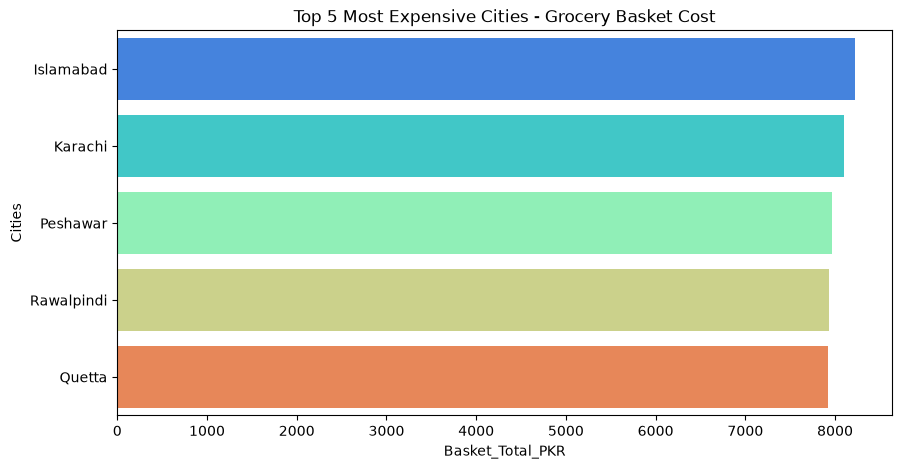

In [36]:
plt.figure(figsize=(10,5))

sns.barplot(
    data= Top5expensivecities,
    x='Basket_Total_PKR',
    y= 'City',
    palette= 'rainbow'
)

plt.title('Top 5 Most Expensive Cities - Grocery Basket Cost')
plt.xlabel('Basket_Total_PKR')
plt.ylabel('Cities')
plt.show()

C:\Users\hp\AppData\Local\Temp\ipykernel_9172\2162963257.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


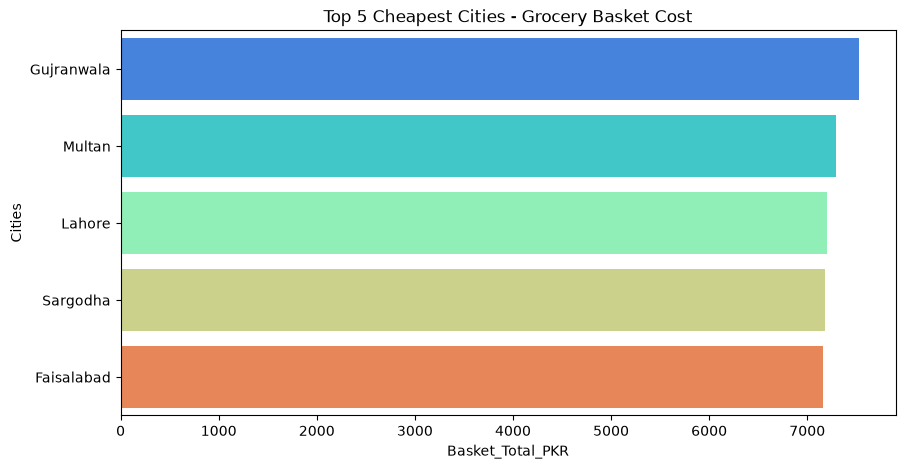

In [37]:
plt.figure(figsize=(10,5))

sns.barplot(
    data= Top5Cheapestcities,
    x='Basket_Total_PKR',
    y= 'City',
    palette= 'rainbow'
)

plt.title('Top 5 Cheapest Cities - Grocery Basket Cost')
plt.xlabel('Basket_Total_PKR')
plt.ylabel('Cities')
plt.show()

In [38]:
difference = (
    Top5expensivecities['Basket_Total_PKR'].max()
    - Top5Cheapestcities['Basket_Total_PKR'].min()
)

difference

np.float64(1062.1900000000005)

## Grocery Basket Analysis - Key Findings

1. Islamabad has the highest grocery basket cost at Rs. 8,226.68.
2. Faisalabad has the lowest grocery basket cost at Rs. 7,164.49.
3. The difference between the most expensive and cheapest city is Rs. 1,062.19.
4. Karachi is the second most expensive city, with a basket cost of Rs. 8,098.75.
5. Lahore has a basket cost of Rs. 7,202.21 and ranks among the five cheapest cities.

### Conclusion

The analysis shows that the cost of the selected 11 grocery items varies across the 17 cities. Islamabad has the highest basket cost, while Faisalabad has the lowest.

Note: This comparison is based on 11 selected items and their original PBS units for September 2026.